# simulation parameters

## Pulse
central wavelength = 1.8 microns $\iff$ 166.55 THz

fwhm = 20 fs

medium thickness = 10 nm

Drude params

silica

transmitted waveform


charge injection timescale = 1 fs = $10^{-3}$ ps

final N = 10^15 

$\omega_D = 0.0488073 \mathrm{fs}^{-1} = 0.0488073\times 10^{15} \mathrm{Hz} = 48.8073 \mathrm{THz} $ [final]  check if these are 2pi times the values

$\gamma_D = 0.30353 \mathrm{fs}^{-1} = 303.53 \mathrm{THz}$ [constant]

n = 1.4
number of delays = 50 [-30, 30] fs = [-0.03, 0.03] ps

# Simulation parameters

thickness = 12.82 $\mu$ m, fused SiO $_2$

In [1]:
from lightmatter.fdtd import run_simulation
from lightmatter.fdtd import PulseParams, MaterialParamsTD, FDTDParams
from lightmatter.io import save_simulation_run, load_simulation_run, make_fdtd_gif
from lightmatter.units import C0,C0_SI, UNIT_T, UNIT_F, UNIT_L

import numpy as np
import matplotlib.pyplot as plt

# FDTD setup

In [2]:
# ------------------ Grid + time ------------------ #
# Lengths in Angstrom; times in ps.
L = 30.0 * 1e4                      # 30 um
dz = 10.0                          # unchanged: 1 nm
Nz = int(L / dz)
dt = 0.99 * dz / C0                 # ~0.00330 fs = 3.30 as, NOT ~3 fs
print(f"dt = {dt*1e3} fs")

# ------------------ Source ------------------ #
src_pos = 10.0 * 1e4                # unchanged: 10 um
src_i = int(np.round(src_pos / dz))

# ------------------ Metal film ------------------ #
x_0 = 15.0 * 1e4                    # film centre: 15 um
thickness = 100.0                   # unchanged: 10 nm

metal_cells = int(np.round(thickness / dz))
metal_center_i = int(np.round(x_0 / dz))
metal_i0 = metal_center_i - metal_cells // 2
metal_i1 = metal_i0 + metal_cells

# ------------------ Probes ------------------ #
probe_r_pos = x_0 - thickness / 2.0 - 2.0 * 1e4
probe_t_pos = x_0 + thickness / 2.0 + 2.0 * 1e4

probe_r_i = int(np.round(probe_r_pos / dz))
probe_t_i = int(np.round(probe_t_pos / dz))

# ------------------ Pulse parameters ------------------ #
E0_VA = 0.1                         # unchanged
E0 = E0_VA * 1.0
f0 = 166.55                        # unchanged: THz

intensity_fwhm = 20.0e-3            # 20 fs in ps
tau = intensity_fwhm / (2.0 * np.sqrt(np.log(2.0)))
t0 = 5.0 * tau                     # ~60.06 fs; negligible initial envelope

pulsetype = "gaussian"
pulse = PulseParams(
    E0=E0,
    f0=f0,
    t0=t0,
    tau=tau,
    phase=0.0,
    type=pulsetype,
)

# ------------------ Total simulation time ------------------ #
# One-way propagation to the transmission probe, followed by
# five Gaussian widths and a further 10 fs recording margin.
travel_time = (probe_t_pos - src_pos) / C0
T_estimate = t0 + travel_time + 5.0 * tau + 10.0e-3

Nt = int(np.ceil(T_estimate / dt))
T = Nt * dt                        # ~0.15348 ps

snap_every_n = 500                  # unchanged
number_of_snaps = (Nt + snap_every_n - 1) // snap_every_n

print(f"Nt={Nt}, number of snaps={number_of_snaps}")
print(f"simulation time: {T:.6f} ps")

#------------------Simulation box parameters (with film)---------------#
simulation_params_withfilm = FDTDParams(
    Nz=Nz,
    Nt=Nt,
    dz=dz,
    dt=dt,
    src_i=src_i,
    probe_t_i=probe_t_i,
    probe_r_i=probe_r_i,
    metal_i0=metal_i0,
    metal_i1=metal_i1,
    snap_every= snap_every_n,  # 0 disables snapshots
)

#------------------Simulation box parameters (without film)---------------#
# simulation_params_nofilm = FDTDParams(
#     Nz=Nz,
#     Nt=Nt,
#     dz=dz,
#     dt=dt,
#     src_i=src_i,
#     probe_t_i=probe_t_i,
#     probe_r_i=probe_r_i,
#     metal_i0=metal_i0,
#     metal_i1=metal_i0, # make metal thickness=0.0
#     snap_every= snap_every_n,  # 0 disables snapshots
# )

dt = 0.0033022845424617053 fs
Nt=46477, number of snaps=93
simulation time: 0.153480 ps


In [3]:
#------------------charge injection---------------#
def omega_D_smoothstep(t, omega0, delta, t0, deltat):
    step = 0.5 * (1.0 + np.tanh((t - t0) / deltat))

    return omega0 + delta * step

t_ax = np.linspace(0.0,T,Nt)

n_background = 1.4409 # at the central wavelength
omega_D0 = 0.0
del_omega_D = 48.8073*50
injection_time = 0.04   # this will be varied
injection_del_t = 1e-3
omega_D_timedep = omega_D_smoothstep(t_ax, omega_D0, del_omega_D, injection_time, injection_del_t)
omega_D_const = np.ones(Nt) * omega_D0

gamma_D0 = 2.0*np.pi*303.53 * 0.01
gamma_D_constant = np.ones(Nt) * gamma_D0

material = MaterialParamsTD(
    omega_D=omega_D_const, 
    gamma_D=gamma_D_constant,
    omega_L=np.ones(Nt) * 2.0*np.pi*1.0,    # placeholder values 
    gamma_L=np.ones(Nt) * 2.0*np.pi*1.0,
    del_eps=np.ones(Nt) * 1.0 *0.0,               #lorentz off
    eps_inf=np.ones(Nt) * n_background**2.0,
)

print(f"simulation time: {T} ps")


simulation time: 0.15348027867999267 ps


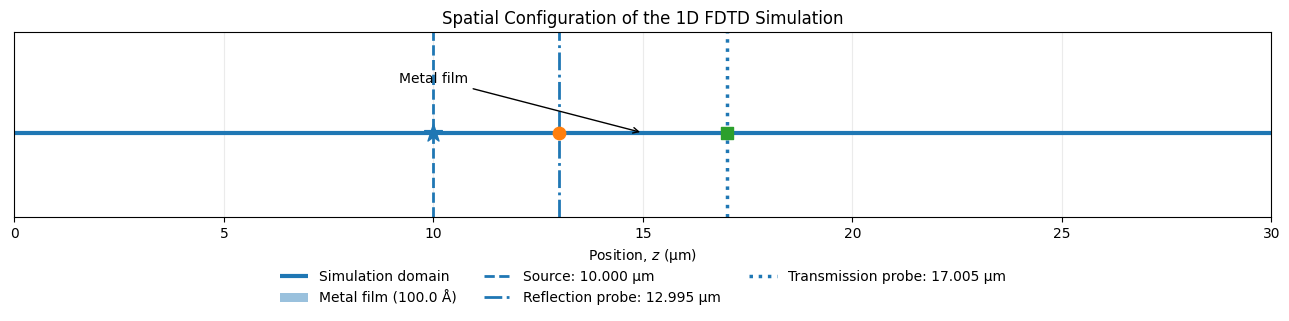

Simulation domain:       0.0000 to 30.0000 μm
Source position:         10.0000 μm
Reflection probe:        12.9950 μm
Transmission probe:      17.0050 μm
Metal region:            14.9950 to 15.0050 μm
Discretized metal width: 100.0 Å


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# Plot the spatial configuration of the FDTD simulation
# -----------------------------------------------------------------------------

# Conversion factor
angstrom_to_um = 1.0e-4

# Full simulation-domain boundaries
domain_left = 0.0
domain_right = Nz * dz

# Actual grid-aligned positions
source_position = src_i * dz
reflection_probe_position = probe_r_i * dz
transmission_probe_position = probe_t_i * dz

metal_left = metal_i0 * dz
metal_right = metal_i1 * dz

# Convert positions from angstroms to micrometres
domain_left_um = domain_left * angstrom_to_um
domain_right_um = domain_right * angstrom_to_um

source_position_um = source_position * angstrom_to_um
reflection_probe_position_um = reflection_probe_position * angstrom_to_um
transmission_probe_position_um = transmission_probe_position * angstrom_to_um

metal_left_um = metal_left * angstrom_to_um
metal_right_um = metal_right * angstrom_to_um

# -----------------------------------------------------------------------------
# Create plot
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 3.5))

# Draw the full simulation region
ax.hlines(
    y=0,
    xmin=domain_left_um,
    xmax=domain_right_um,
    linewidth=3,
    label="Simulation domain",
)

# Shade the metal film
ax.axvspan(
    metal_left_um,
    metal_right_um,
    alpha=0.45,
    label=f"Metal film ({thickness:.1f} Å)",
)

# Source
ax.axvline(
    source_position_um,
    linestyle="--",
    linewidth=2,
    label=f"Source: {source_position_um:.3f} μm",
)

# Reflection probe
ax.axvline(
    reflection_probe_position_um,
    linestyle="-.",
    linewidth=2,
    label=f"Reflection probe: {reflection_probe_position_um:.3f} μm",
)

# Transmission probe
ax.axvline(
    transmission_probe_position_um,
    linestyle=":",
    linewidth=2.5,
    label=f"Transmission probe: {transmission_probe_position_um:.3f} μm",
)

# Add markers along the simulation line
ax.scatter(source_position_um, 0, marker="*", s=180, zorder=5)
ax.scatter(reflection_probe_position_um, 0, marker="o", s=80, zorder=5)
ax.scatter(transmission_probe_position_um, 0, marker="s", s=80, zorder=5)

# Label the metal position because the film is very thin on the full-domain plot
ax.annotate(
    "Metal film",
    xy=((metal_left_um + metal_right_um) / 2, 0),
    xytext=(metal_left_um - 5, 0.45),
    arrowprops=dict(arrowstyle="->"),
    horizontalalignment="center",
)

# Formatting
ax.set_xlim(domain_left_um, domain_right_um)
ax.set_ylim(-0.75, 0.9)

ax.set_xlabel("Position, $z$ (μm)")
ax.set_yticks([])
ax.set_title("Spatial Configuration of the 1D FDTD Simulation")

ax.grid(axis="x", alpha=0.25)
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
)

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# Print exact grid-aligned positions
# -----------------------------------------------------------------------------
print(f"Simulation domain:       {domain_left_um:.4f} to {domain_right_um:.4f} μm")
print(f"Source position:         {source_position_um:.4f} μm")
print(f"Reflection probe:        {reflection_probe_position_um:.4f} μm")
print(f"Transmission probe:      {transmission_probe_position_um:.4f} μm")
print(f"Metal region:            {metal_left_um:.4f} to {metal_right_um:.4f} μm")
print(f"Discretized metal width: {(metal_right - metal_left):.1f} Å")

In [5]:
travel_to_probe = (probe_t_i - metal_center_i) * dz / C0
print(travel_to_probe * 1e3)

6.687960108722949


In [6]:
t_pulse_at_film = t0 + (metal_i0 - src_i) * dz / C0
print(f"{t_pulse_at_film:.4f}")
print(f"injection scan limits: {t_pulse_at_film-0.03:.2f},{t_pulse_at_film+0.03:.2f}")

0.0767
injection scan limits: 0.05,0.11


# Run simulation

In [7]:
gamma_chosen = 0.01
injection_times_arr = np.linspace(0.05,0.11,100)

for inj_time in injection_times_arr:

    dirname = f"project2/gamma_{gamma_chosen:.2f}_highomega/inj_time_{inj_time:.4f}" #------------------------------------- ####    change

    omega_D_timedep = omega_D_smoothstep(t_ax, omega_D0, del_omega_D, inj_time, injection_del_t)

    material = MaterialParamsTD(
        omega_D=omega_D_timedep, 
        gamma_D=gamma_D_constant,
        omega_L=np.ones(Nt) * 2.0*np.pi*1.0,    # placeholder values 
        gamma_L=np.ones(Nt) * 2.0*np.pi*1.0,
        del_eps=np.ones(Nt) * 1.0 *0.0,               #lorentz off
        eps_inf=np.ones(Nt) * n_background**2.0,
    )

    E_t, E_r, snaps_t, snaps_E = run_simulation(simulation_params_withfilm, pulse, material, method="exact pml")

    save_simulation_run(
        folder=f"../../output/{dirname}/with_film",
        params=simulation_params_withfilm, 
        pulse=pulse,
        material=material,
        E_t=E_t,
        E_r=E_r,
        snaps_t=snaps_t,
        snaps_E=snaps_E,
    )


# static case
material = MaterialParamsTD(
    omega_D=omega_D_const, 
    gamma_D=gamma_D_constant,
    omega_L=np.ones(Nt) * 2.0*np.pi*1.0,    # placeholder values 
    gamma_L=np.ones(Nt) * 2.0*np.pi*1.0,
    del_eps=np.ones(Nt) * 1.0 *0.0,               #lorentz off
    eps_inf=np.ones(Nt) * n_background**2.0,
)

E_t, E_r, snaps_t, snaps_E = run_simulation(simulation_params_withfilm, pulse, material, method="exact pml")

save_simulation_run(
    folder=f"../../output/project2/gamma_{gamma_chosen:.2f}_highomega/static/with_film", #-------------------------------------####    change
    params=simulation_params_withfilm, 
    pulse=pulse,
    material=material,
    E_t=E_t,
    E_r=E_r,
    snaps_t=snaps_t,
    snaps_E=snaps_E,
)


Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0500/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0506/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0512/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0518/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0524/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0530/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0536/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0542/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0548/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0555/with_film
Simulation saved to: ../../output/project2/gamma_0.01_highomega/inj_time_0.0561/with_film
Simulation

# Retrieve

In [8]:
# inj_time_retr = 0.04
# for inj_time_retr in [0.05,]:
#     print(inj_time_retr)

#     # dirname_const = f"project2/intermediate_gamma/inj_time_{inj_time_retr:.4f}"
#     dirname_const = f"project2/static"

#     result_withfilm = load_simulation_run(f"../../output/{dirname_const}/with_film",nosnaps=False)

#     E_t_const = result_withfilm["E_t"]

#     Nt = result_withfilm["params"].Nt
#     dt = result_withfilm["params"].dt * UNIT_T
#     dz_retrieved = result_withfilm["params"].dz * UNIT_L
#     t_ax_retrieved = np.arange(Nt) * dt
#     f0 = result_withfilm["pulse"].f0 * UNIT_F
#     thickness_retrieved = (result_withfilm['params'].metal_i1 - result_withfilm['params'].metal_i0) * result_withfilm['params'].dz * UNIT_L

#     simulation_params_withfilm = result_withfilm['params']
#     plt.plot(t_ax_retrieved, E_t_const)
#     # plt.yscale("log")
#     plt.grid(True)

In [9]:
every_frame = 92
frame_num = 1

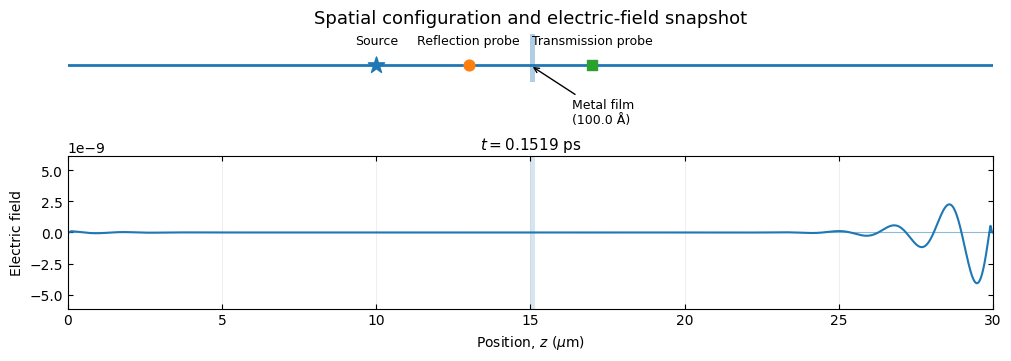

In [9]:
snaps_t = result_withfilm["snaps_t"]
snaps_E = result_withfilm["snaps_E"]

if snaps_E.ndim != 2:
    raise ValueError("snaps_E must be 2D with shape (Nsnap, Nz).")
if snaps_t.shape[0] != snaps_E.shape[0]:
    raise ValueError("snaps_t and snaps_E must have the same length.")

# Subsample frames if requested
frame_idx = np.arange(0, snaps_t.shape[0], every_frame, dtype=int)
if frame_idx.size == 0:
    raise ValueError("No frames selected. Check every_frame and snapshot arrays.")

Nz = snaps_E.shape[1]
z_um = np.arange(Nz) * dz * 1e-4 # change units to microns
dz_um = dz * 1e-4

# Fixed y-limits for stable visualization
Emax = float(np.max(np.abs(snaps_E[frame_idx, :])))
if Emax == 0.0:
    Emax = 1.0



# Conversion factor
angstrom_to_um = 1.0e-4

# Full simulation-domain boundaries
domain_left = 0.0
domain_right = Nz * dz

# Actual grid-aligned positions
source_position = src_i * dz
reflection_probe_position = probe_r_i * dz
transmission_probe_position = probe_t_i * dz

metal_left = metal_i0 * dz
metal_right = metal_i1 * dz

# Convert positions from angstroms to micrometres
domain_left_um = domain_left * angstrom_to_um
domain_right_um = domain_right * angstrom_to_um

source_position_um = source_position * angstrom_to_um
reflection_probe_position_um = reflection_probe_position * angstrom_to_um
transmission_probe_position_um = transmission_probe_position * angstrom_to_um

metal_left_um = metal_left * angstrom_to_um
metal_right_um = metal_right * angstrom_to_um

# -----------------------------------------------------------------------------
# Select snapshot
# -----------------------------------------------------------------------------

if not 0 <= frame_num < len(frame_idx):
    raise IndexError(
        f"frame_num={frame_num} is outside the available range "
        f"0 to {len(frame_idx) - 1}."
    )

snapshot_index = frame_idx[frame_num]
snapshot_time = snaps_t[snapshot_index]
snapshot_field = snaps_E[snapshot_index, :]


# -----------------------------------------------------------------------------
# Create a cleaner two-panel plot
# -----------------------------------------------------------------------------

fig, (ax_setup, ax_field) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(10, 3.5),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1.0, 3.2],
        "hspace": 0.05,
    },
    constrained_layout=True,
)


# =============================================================================
# Top panel: simulation geometry
# =============================================================================

ax_setup.axhline(
    0.0,
    linewidth=2.0,
)

# Metal film
ax_setup.axvspan(
    metal_left_um,
    metal_right_um*1.01,
    alpha=0.35,
)

# Source and probes
setup_positions = [
    source_position_um,
    reflection_probe_position_um,
    transmission_probe_position_um,
]

setup_markers = [
    "*",
    "o",
    "s",
]

setup_labels = [
    "Source",
    "Reflection probe",
    "Transmission probe",
]

setup_sizes = [
    150,
    60,
    60,
]

for position, marker, label, size in zip(
    setup_positions,
    setup_markers,
    setup_labels,
    setup_sizes,
):
    ax_setup.scatter(
        position,
        0.0,
        marker=marker,
        s=size,
        zorder=4,
    )

    ax_setup.annotate(
        label,
        xy=(position, 0.0),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9,
    )

# Label the thin metal film with an offset arrow.
metal_center_um = 0.5 * (
    metal_left_um + metal_right_um
)

ax_setup.annotate(
    f"Metal film\n({thickness:.1f} Å)",
    xy=(metal_center_um, 0.0),
    xytext=(30, -24),
    textcoords="offset points",
    ha="left",
    va="top",
    fontsize=9,
    arrowprops={
        "arrowstyle": "->",
        "linewidth": 1.0,
    },
)

ax_setup.set_ylim(
    -0.35,
    0.65,
)

ax_setup.set_yticks([])
ax_setup.tick_params(
    axis="x",
    which="both",
    bottom=False,
    labelbottom=False,
)

ax_setup.spines["left"].set_visible(False)
ax_setup.spines["right"].set_visible(False)
ax_setup.spines["top"].set_visible(False)
ax_setup.spines["bottom"].set_visible(False)

ax_setup.set_title(
    "Spatial configuration and electric-field snapshot",
    fontsize=13,
    pad=8,
)


# =============================================================================
# Bottom panel: electric-field snapshot
# =============================================================================

ax_field.plot(
    z_um,
    snapshot_field*1e-6,
    linewidth=1.5,
)

ax_field.axhline(
    0.0,
    linewidth=0.8,
    alpha=0.5,
)

# Show only the metal region in the field panel.
ax_field.axvspan(
    metal_left_um,
    metal_right_um*1.01,
    alpha=0.18,
)

ax_field.set_xlim(
    domain_left_um,
    domain_right_um,
)

ax_field.set_ylim(
    -1.5 * Emax*1e-6,
    1.5 * Emax*1e-6,
)

ax_field.set_xlabel(
    r"Position, $z$ ($\mu$m)",
)

ax_field.set_ylabel(
    "Electric field",
)

ax_field.set_title(
    rf"$t = {snapshot_time:.4f}$ ps",
    fontsize=11,
    pad=5,
)

ax_field.grid(
    axis="x",
    alpha=0.2,
)

ax_field.tick_params(
    direction="in",
    top=True,
    right=True,
)
plt.savefig("fdtd_setup.pdf")

plt.show()

# Integrated Analysis
Make an integral of total energy in the transmitted pulse as a function of the injection time

In [ ]:
# make a gaussian filter
# def apply_gaussian_filter(E_signal,T_signal,f0 = 166e12, bandwidth = 30e12):

#     # Time step
#     dt_signal = np.mean(np.diff(T_signal))

#     # Fourier transform
#     freq = np.fft.fftfreq(len(E_signal), d=dt_signal)
#     E_fft = np.fft.fft(E_signal)

#     # Convert FWHM -> sigma
#     sigma_f = bandwidth / (2 * np.sqrt(2 * np.log(2)))

#     # Gaussian filter at both +f0 and -f0
#     gaussian_filter = (
#         np.exp(-0.5 * ((freq - f0) / sigma_f)**2)
#         + np.exp(-0.5 * ((freq + f0) / sigma_f)**2)
#     )

#     # Apply filter and transform back
#     E_filtered = np.real(np.fft.ifft(E_fft * gaussian_filter))

#     return E_filtered

In [9]:
# do integrated analysis
from scipy.integrate import cumulative_trapezoid

def complete_integral_analysis(directory):

    injection_times_arr_int = np.linspace(0.05,0.11,100)
    energy_arr_int = np.zeros_like(injection_times_arr_int)

    for i,inj_time_retr in enumerate(injection_times_arr_int):
        
        result_withfilm = load_simulation_run(f"../../output/project2/{directory}/inj_time_{inj_time_retr:.4f}/with_film",nosnaps=True)

        E_t = result_withfilm["E_t"]

        Nt = result_withfilm["params"].Nt
        dt = result_withfilm["params"].dt * UNIT_T
        dz_retrieved = result_withfilm["params"].dz * UNIT_L
        t_ax_retrieved = np.arange(Nt) * dt

        energy_arr_int[i] = np.sum(np.power(E_t,2.0)) *  dt

    
    result_withfilm = load_simulation_run(f"../../output/project2/{directory}/static/with_film",nosnaps=False)

    E_t_static = result_withfilm["E_t"]

    Nt = result_withfilm["params"].Nt
    dt = result_withfilm["params"].dt * UNIT_T
    dz_retrieved = result_withfilm["params"].dz * UNIT_L
    t_ax_retrieved_static = np.arange(Nt) * dt

    energy_static = np.sum(np.power(E_t_static,2.0)) *  dt

    # Vector potential: E = -dA/dt
    vector_pot = -cumulative_trapezoid(
        E_t_static,
        t_ax_retrieved_static,
        initial=0.0
    )

    travel_to_probe_SI = (result_withfilm["params"].probe_t_i - 0.5*(result_withfilm["params"].metal_i0+result_withfilm["params"].metal_i1)) * dz_retrieved / C0_SI

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # Energy change curves: left y-axis
    ax1.plot(
        injection_times_arr_int * 1e3,
        (energy_arr_int / energy_static - 1.0) * 100,
        linewidth=2,
        label=r"percentage change in energy"
    )

    ax1.set_xlabel("Injection time (at film)[fs]", fontsize=12)
    ax1.set_ylabel("Percentage change in energy [%]", fontsize=12)
    ax1.grid(True, alpha=0.3)

    ax1.set_title("Integrated change in pulse energy as a function of the injection time")

    # Electric field: right y-axis
    ax2 = ax1.twinx()

    ax2.plot(
        t_ax_retrieved * 1e15 - travel_to_probe_SI*1e15,
        E_t_static,
        linewidth=1,
        color="black",
        alpha = 0.5,
        linestyle="--",
        label="Electric field (at film)"
    )

    ax2.plot(
        t_ax_retrieved * 1e15 - travel_to_probe_SI*1e15,
        vector_pot*1e15,
        linewidth=1,
        color="blue",
        alpha = 0.5,
        linestyle="--",
        label="Vector potential (at film)"
    )

    ax2.set_ylabel("Electric field")
    ax1.set_xlim((50,110))

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(lines1 + lines2, labels1 + labels2)

    plt.tight_layout()
    plt.show()

    return energy_arr_int / energy_static

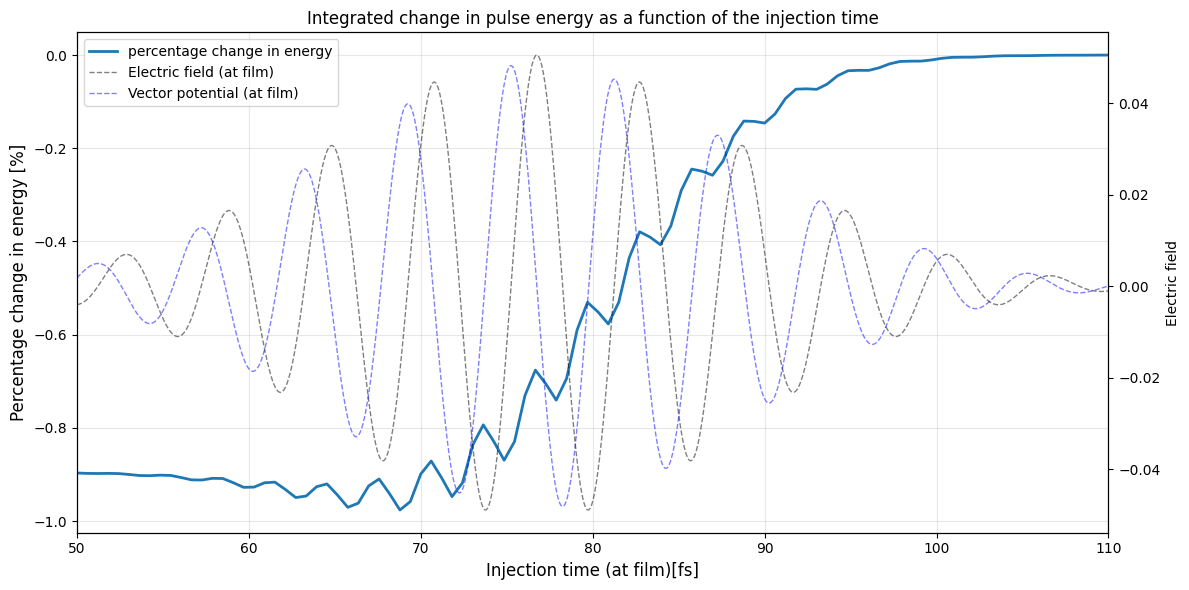

In [10]:
arr = complete_integral_analysis("gamma_0.01_highomega")

In [11]:
# from scipy.signal import butter, sosfiltfilt
# from scipy.integrate import cumulative_trapezoid

# # Time step and sampling frequency
# dt = np.mean(np.diff(t_ax_retrieved))
# fs = 1.0 / dt

# lowcut  = 1e12
# highcut = 1000e12

# sos = butter(
#     4,
#     [lowcut, highcut],
#     btype="bandpass",
#     fs=fs,
#     output="sos"
# )

# E_filtered = sosfiltfilt(sos, E_t_const)

# vector_pot = -cumulative_trapezoid(
#     E_filtered,
#     t_ax_retrieved,
#     initial=0.0
# )

# Fixed cycle analysis

For a particular cycle, say the one close to 83.4 fs, evaluate the energy of that cycle as a function of the injection time.

This analysis must be done with the unfiltered electric fields

In [12]:
from lightmatter.peak_analyzer_interpolate import _zero_crossings_linear
from scipy.signal import find_peaks
from scipy.integrate import simpson, trapezoid

def peak_lobe_energy(t,E,travel_to_probe_SI, t_closest_SI = 88.68*1e-15, peak_type="positive"):

    if peak_type=="positive":
        peaks,_ = find_peaks(E)
    elif peak_type=="negative":
        peaks,_ = find_peaks(-E)
    else:
        raise ValueError("Invalid peak type")

    id_selected = np.argmin(np.abs((t[peaks]-travel_to_probe_SI) - t_closest_SI))
    peak_id = peaks[id_selected]

    # Find interpolated zero-crossing times.
    z_times, _, _ = _zero_crossings_linear(E, t)

    # Include exactly sampled zeros, including a possible final-sample zero.
    z_times = np.unique(np.r_[z_times, t[E == 0.0]])

    # Select the nearest zeros strictly before and after the chosen peak.
    t_peak = t[peak_id]
    zeros_before = z_times[z_times < t_peak]
    zeros_after = z_times[z_times > t_peak]

    if zeros_before.size == 0 or zeros_after.size == 0:
        raise ValueError("The selected peak is not bounded by zeros on both sides.")

    t_left = zeros_before[-1]
    t_right = zeros_after[0]

    # Retain interior samples and add the interpolated zero-valued endpoints.
    inside = (t > t_left) & (t < t_right)
    t_interval = np.r_[t_left, t[inside], t_right]
    E_interval = np.r_[0.0, E[inside], 0.0]

    integral_E2 = trapezoid(E_interval**2.0, t_interval)

    return integral_E2

In [13]:
def fixed_cycle(directory,closest_peak_time_SI,peak_type="positive"):

    #load static case
    result_withfilm = load_simulation_run(f"../../output/project2/{directory}/static/with_film",nosnaps=False)
    E_t_static = result_withfilm["E_t"]
    Nt = result_withfilm["params"].Nt
    dt = result_withfilm["params"].dt * UNIT_T
    dz_retrieved = result_withfilm["params"].dz * UNIT_L
    t_ax_retrieved_static = np.arange(Nt) * dt

    vector_pot_unfiltered = -cumulative_trapezoid(
        E_t_static,
        t_ax_retrieved_static,
        initial=0.0
    )

    travel_to_probe_SI = (result_withfilm["params"].probe_t_i - 0.5*(result_withfilm["params"].metal_i0+result_withfilm["params"].metal_i1)) * dz_retrieved / C0_SI

    lobe_energy_static = peak_lobe_energy(t_ax_retrieved_static, E_t_static, travel_to_probe_SI, peak_type=peak_type, t_closest_SI=closest_peak_time_SI)

    injection_times_arr_int = np.linspace(0.05,0.11,100)
    lobe_energy = np.zeros_like(injection_times_arr_int)

    for i,inj_time_retr in enumerate(injection_times_arr_int):
        
        dirname_const = f"project2/{directory}/inj_time_{inj_time_retr:.4f}"

        result_withfilm = load_simulation_run(f"../../output/{dirname_const}/with_film",nosnaps=True)

        E_t = result_withfilm["E_t"]

        Nt = result_withfilm["params"].Nt
        dt = result_withfilm["params"].dt * UNIT_T
        dz_retrieved = result_withfilm["params"].dz * UNIT_L
        t_ax_retrieved = np.arange(Nt) * dt

        lobe_energy[i] = peak_lobe_energy(t_ax_retrieved, E_t, travel_to_probe_SI, peak_type=peak_type, t_closest_SI=closest_peak_time_SI)


    fig, ax1 = plt.subplots(figsize=(12, 6))

    # Energy change curves: left y-axis
    ax1.plot(
        injection_times_arr_int * 1e3,
        lobe_energy / lobe_energy_static,
        linewidth=2,
        label=r"lobe energy"
    )

    ax1.set_xlabel("Injection time (at film)[fs]", fontsize=12)
    ax1.set_ylabel("Lobe energy", fontsize=12)
    ax1.grid(True, alpha=0.3)

    ax1.axvline(closest_peak_time_SI*1e15,linestyle="--",color="black",linewidth=1)

    # Electric field: right y-axis
    ax2 = ax1.twinx()

    ax2.plot(
        (t_ax_retrieved - travel_to_probe_SI)*1e15,
        E_t_static,
        linewidth=1,
        color="black",
        alpha = 0.5,
        linestyle="--",
        label="Electric field (at film)"
    )

    ax2.plot(
        t_ax_retrieved * 1e15 - travel_to_probe_SI*1e15,
        vector_pot_unfiltered*1e15,
        linewidth=1,
        color="blue",
        alpha = 0.5,
        linestyle="--",
        label="Vector potential (at film)"
    )

    ax2.set_ylabel("Electric field")
    ax1.set_xlim((45,115))

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax1.legend(lines1 + lines2, labels1 + labels2)

    plt.tight_layout()
    plt.show()

    return lobe_energy / lobe_energy_static

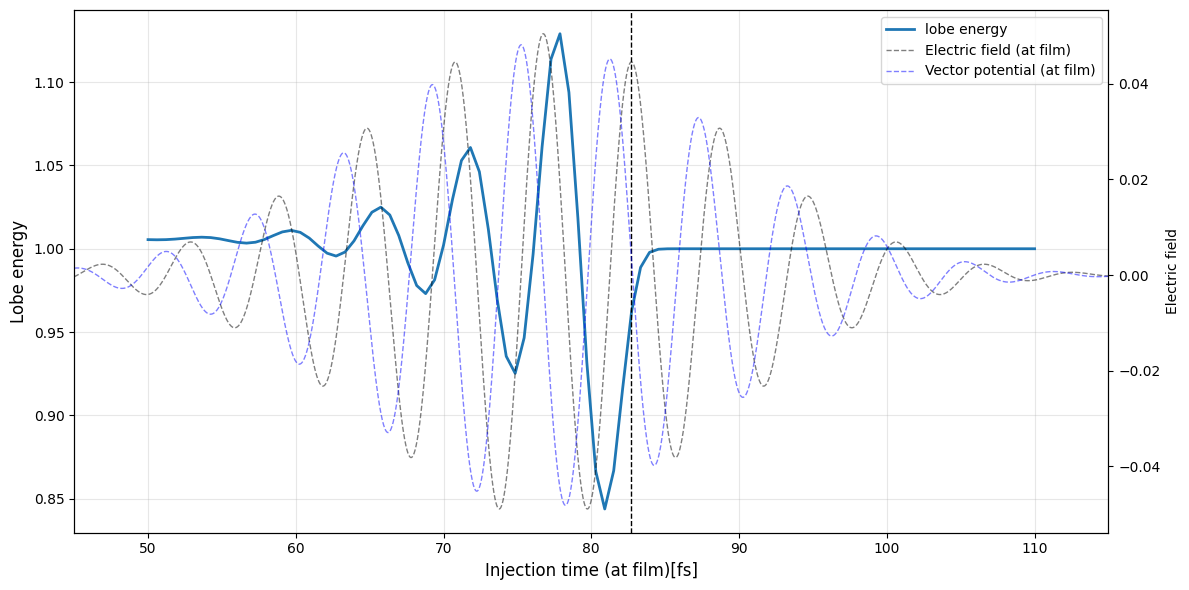

In [17]:
arr_lobe = fixed_cycle("gamma_0.01_highomega",82.7*1e-15,
                       peak_type="positive",
                    #    peak_type="negative",
                       )

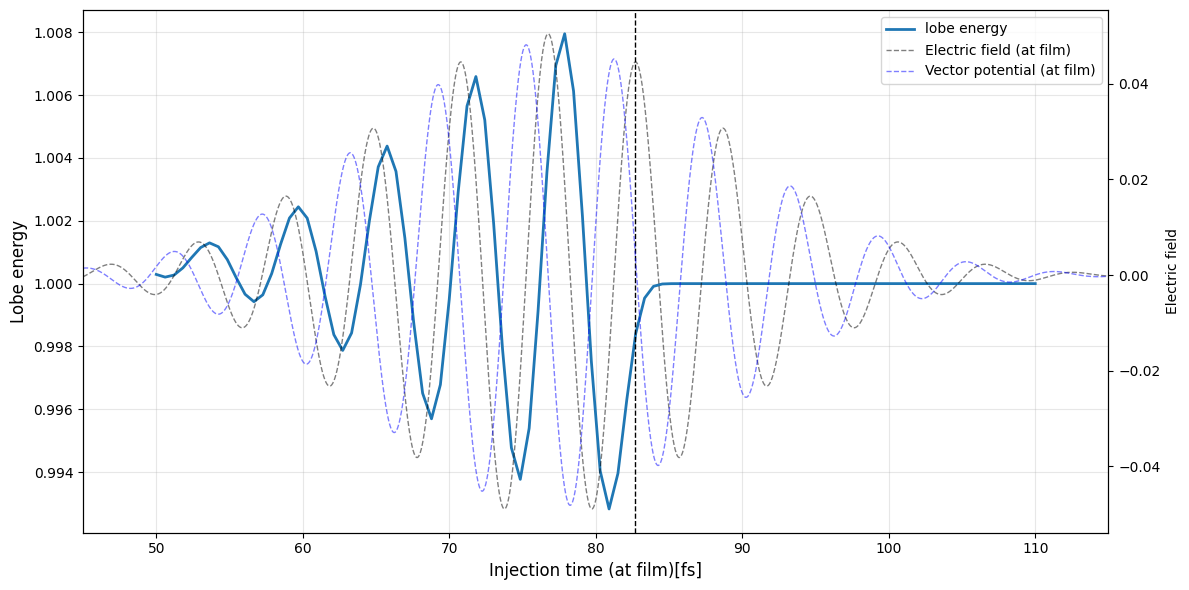

In [18]:
arr_lobe = fixed_cycle("gamma_0.01",82.7*1e-15,
                       peak_type="positive",
                    #    peak_type="negative",
                       )

# old code

In [ ]:
from scipy.signal import find_peaks

peaks,_ = find_peaks(E_t_static)
peaks_neg,_ = find_peaks(-E_t_static)

# find exact time of arrival of the peak at the film
(t_ax_retrieved_static[peaks] - travel_to_probe_SI)*1e15

#this is useful for choosing a particular peak later

array([ 16.71202816,  16.74174872,  16.76486471,  16.78467842,
        16.80449213,  16.82100355,  16.83751497,  16.85402639,
        16.87053782,  16.88704924,  16.90025838,  16.9167698 ,
        16.92997894,  16.94649036,  16.9596995 ,  16.97290864,
        16.98942006,  17.0026292 ,  17.01583834,  17.02904748,
        17.0455589 ,  17.05876804,  17.07197717,  17.0884886 ,
        17.10169774,  17.11820916,  17.1314183 ,  17.151232  ,
        17.16444114,  17.18095256,  17.1941617 ,  17.20737084,
        17.22057998,  17.2370914 ,  17.25030054,  17.26350968,
        17.2800211 ,  17.29323024,  17.30643938,  17.3229508 ,
        17.33615994,  17.34936908,  17.36257821,  17.37578735,
        17.39229877,  17.40550791,  17.41871705,  17.43192619,
        17.44513533,  17.45834447,  17.4715536 ,  17.48476274,
        17.50127416,  17.5144833 ,  17.52769244,  17.54090158,
        17.557413  ,  17.57062214,  17.58383128,  17.59704042,
        17.61355184,  17.62676098,  17.63997012,  17.65

In [14]:
chosen_peak_time_approx = 88.68
# chosen_peak_time_approx = 85.7 # for the negative choice

id_selected = np.argmin(np.abs((t_ax_retrieved_static[peaks] - travel_to_probe_SI)*1e15 - chosen_peak_time_approx)) # chosen peak
peak_id = peaks[id_selected]
# peak_id = peaks_neg[id_selected]

E_t_static[peak_id],t_ax_retrieved_static[peak_id]*1e15 - travel_to_probe_SI*1e15

# perform an integral of E^2 within the peaks immediately before and after this peak

(np.float64(0.03073090354043902), np.float64(88.68531976211355))

In [15]:
import numpy as np
from lightmatter.peak_analyzer_interpolate import _zero_crossings_linear
from scipy.integrate import trapezoid,simpson

t = np.asarray(t_ax_retrieved_static, dtype=float)  # seconds
E = np.asarray(E_t_static, dtype=float)

# Find interpolated zero-crossing times.
z_times, _, _ = _zero_crossings_linear(E, t)

# Include exactly sampled zeros, including a possible final-sample zero.
z_times = np.unique(np.r_[z_times, t[E == 0.0]])

# Select the nearest zeros strictly before and after the chosen peak.
t_peak = t[peak_id]
zeros_before = z_times[z_times < t_peak]
zeros_after = z_times[z_times > t_peak]

if zeros_before.size == 0 or zeros_after.size == 0:
    raise ValueError("The selected peak is not bounded by zeros on both sides.")

t_left = zeros_before[-1]
t_right = zeros_after[0]

# Retain interior samples and add the interpolated zero-valued endpoints.
inside = (t > t_left) & (t < t_right)
t_interval = np.r_[t_left, t[inside], t_right]
E_interval = np.r_[0.0, E[inside], 0.0]

# Exact integral of the square of a linear function on each subinterval.
E_left = E_interval[:-1]
E_right = E_interval[1:]

integral_E2 = np.sum(
    np.diff(t_interval)
    * (E_left**2 + E_left * E_right + E_right**2)
    / 3.0
)

integral_E2_trap = simpson(E_interval**2.0, t_interval)

print(f"Zero-crossing interval: [{t_left * 1e15:.6f}, "
      f"{t_right * 1e15:.6f}] fs")
print(f"Zero-crossing interval [shifted]: [{(t_left-travel_to_probe_SI) * 1e15:.6f}, "
      f"{(t_right-travel_to_probe_SI) * 1e15:.6f}] fs")
print(f"Integral of E^2 dt exact: {integral_E2:.8e}, from simpson:{integral_E2_trap:.8e}")

Zero-crossing interval: [93.945956, 96.948064] fs
Zero-crossing interval [shifted]: [87.257996, 90.260104] fs
Integral of E^2 dt exact: 1.41156535e-18, from simpson:1.41156818e-18


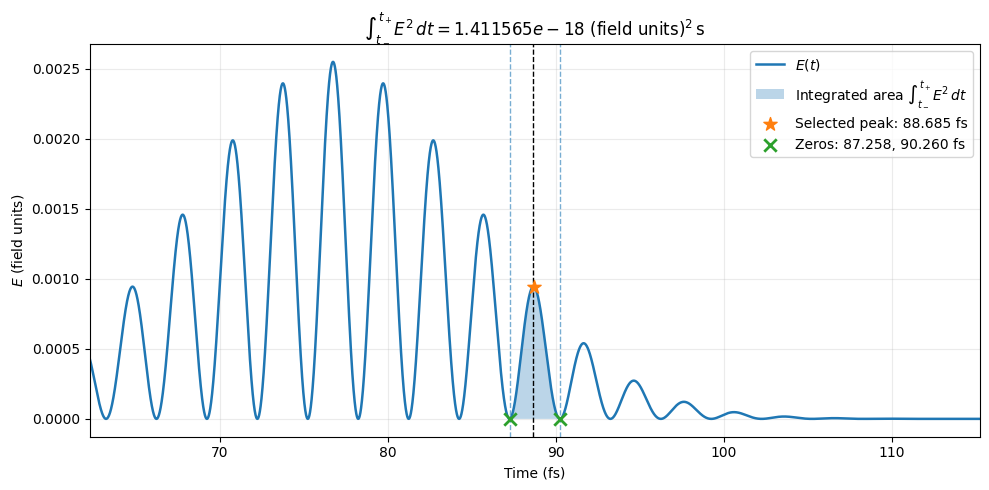

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# shift the lft and right times, w.r.t. travel time
t_left = t_left - travel_to_probe_SI
t_right = t_right - travel_to_probe_SI
t_interval = t_interval - travel_to_probe_SI

# Interpolate E before squaring, consistent with the integration method.
t_fill = np.unique(
    np.r_[t_interval, np.linspace(t_left, t_right, 1000)]
)
E2_fill = np.interp(t_fill, t_interval, E_interval**2.0)

margin_fs = 25.0  # Additional time shown on either side of the interval

fig, ax = plt.subplots(figsize=(10, 5))

# Squared electric-field waveform
ax.plot((t-travel_to_probe_SI) * 1e15, E**2.0, linewidth=1.8, label=r"$E(t)$")

# Shade only the integrated interval, including interpolated endpoints.
ax.fill_between(
    t_fill * 1e15,
    0.0,
    E2_fill,
    alpha=0.3,
    label=r"Integrated area $\int_{t_-}^{t_+} E^2\,dt$",
)

# Mark the selected field peak on the E^2 curve.
ax.scatter(
    (t[peak_id]-travel_to_probe_SI) * 1e15,
    E[peak_id]**2.0,
    marker="*",
    s=100,
    zorder=5,
    label=f"Selected peak: {(t[peak_id]-travel_to_probe_SI) * 1e15:.3f} fs",
)

# Mark the two bounding zero crossings.
ax.scatter(
    np.array([t_left, t_right]) * 1e15,
    [0.0, 0.0],
    marker="x",
    s=80,
    linewidths=2,
    zorder=5,
    label=f"Zeros: {t_left * 1e15:.3f}, {t_right * 1e15:.3f} fs",
)

ax.axvline(chosen_peak_time_approx,linestyle="--",color="black",linewidth=1)

for tz in (t_left, t_right):
    ax.axvline(tz * 1e15, linestyle="--", linewidth=1, alpha=0.6)

ax.set_xlim(
    t_left * 1e15 - margin_fs,
    t_right * 1e15 + margin_fs,
)
ax.set_xlabel("Time (fs)")
ax.set_ylabel(r"$E$ (field units)")
ax.set_title(
    rf"$\int_{{t_-}}^{{t_+}} E^2\,dt = {integral_E2:.6e}$"
    r" (field units)$^2\,\mathrm{s}$"
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

In [18]:
injection_times_arr_int = np.linspace(0.05,0.11,100)
lobe_energy = np.zeros_like(injection_times_arr_int)

for i,inj_time_retr in enumerate(injection_times_arr_int):
    
    dirname_const = f"project2/gamma_0.05/inj_time_{inj_time_retr:.4f}"

    result_withfilm = load_simulation_run(f"../../output/{dirname_const}/with_film",nosnaps=True)

    E_t = result_withfilm["E_t"]

    Nt = result_withfilm["params"].Nt
    dt = result_withfilm["params"].dt * UNIT_T
    dz_retrieved = result_withfilm["params"].dz * UNIT_L
    t_ax_retrieved = np.arange(Nt) * dt
    thickness_retrieved = (result_withfilm['params'].metal_i1 - result_withfilm['params'].metal_i0) * result_withfilm['params'].dz * UNIT_L

    simulation_params_withfilm = result_withfilm['params']

    lobe_energy[i] = peak_lobe_energy(t_ax_retrieved, E_t, t_closest_SI=chosen_peak_time_approx*1e-15)

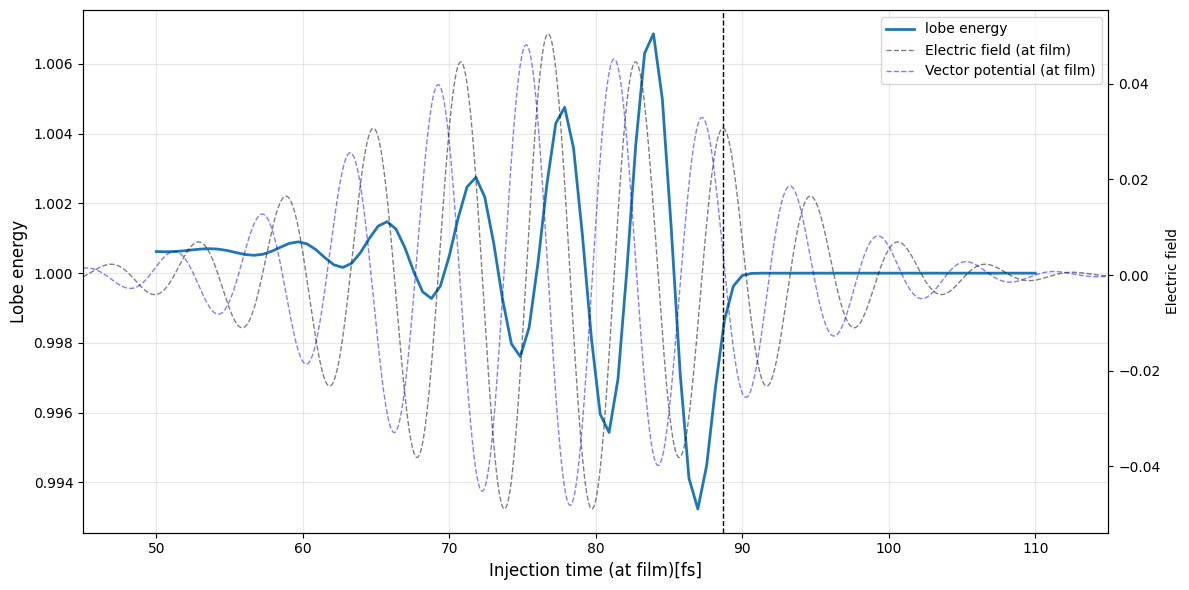

In [19]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Energy change curves: left y-axis
ax1.plot(
    injection_times_arr_int * 1e3,
    lobe_energy / lobe_energy[-1],
    linewidth=2,
    label=r"lobe energy"
)

ax1.set_xlabel("Injection time (at film)[fs]", fontsize=12)
ax1.set_ylabel("Lobe energy", fontsize=12)
ax1.grid(True, alpha=0.3)

ax1.axvline(chosen_peak_time_approx,linestyle="--",color="black",linewidth=1)

# Electric field: right y-axis
ax2 = ax1.twinx()

ax2.plot(
    (t_ax_retrieved - travel_to_probe_SI)*1e15,
    E_t_static,
    linewidth=1,
    color="black",
    alpha = 0.5,
    linestyle="--",
    label="Electric field (at film)"
)

ax2.plot(
    t_ax_retrieved * 1e15 - travel_to_probe_SI*1e15,
    vector_pot_unfiltered*1e15,
    linewidth=1,
    color="blue",
    alpha = 0.5,
    linestyle="--",
    label="Vector potential (at film)"
)

ax2.set_ylabel("Electric field")
ax1.set_xlim((45,115))

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.tight_layout()
plt.show()